# 2º Trabalho de Fundamentos de IA — Etapa 5: Redes Bayesianas
**Domínio:** Educação (SAEB 2021/2023 + Censo 2010) · **IComp/UFAM** · Prof. Edjard Mota

Esta etapa cobre as 6 tarefas do enunciado:

1. **DAG** com 4–6 nós, justificando cada aresta
2. **CPTs** estimadas a partir dos dados
3. **Inferência por enumeração** implementada do zero
4. Comparação com o **pgmpy** (`VariableElimination`)
5. **d-separação**: verificar independências condicionais (e demonstrar um **colisor**)
6. **Economia de parâmetros** frente à conjunta completa

E, para ligar com o pipeline, a rede também é usada como **classificador** de `ALVO_MELHORA` (mesma validação das Etapas 1, 2 e 4).

> Mesmo conjunto das Etapas 1–4 (3.519 exemplos: município × dependência × localização). A rede descreve **associações** entre variáveis; as setas seguem a ordem do tempo e da lógica do domínio (Censo 2010 → SAEB 2021 → SAEB 2023), mas **não provam efeito causal** do Novo Ensino Médio.

## 0. Configuração e variáveis binárias

In [1]:
# pgmpy é usado só na Tarefa 4 (comparação). No Colab: instala se faltar.
import importlib.util, subprocess, sys
if importlib.util.find_spec('pgmpy') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'pgmpy'])

In [2]:
import io, gzip, base64, warnings, itertools
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)
pd.set_option('display.width', 160, 'display.max_columns', 30)

# Conjunto das Etapas 1-4 (SAEB 2021 + SAEB 2023 + IDHM_R do Censo 2010), embutido para dispensar uploads.
EMBUTIDO = "..."
df = pd.read_csv(io.StringIO(gzip.decompress(base64.b64decode(EMBUTIDO)).decode()))

# Cinco variáveis binárias (1 = verdadeiro). B, I e M são as mesmas da Etapa 3.
d = pd.DataFrame({
    'R': (df.CO_UF // 10).isin([1, 2]).astype(int),                 # R: município do Norte ou Nordeste
    'I': (df.IDHM_R < 0.6).astype(int),                              # I: IDHM-Renda (2010) BAIXO (< 0,6)
    'U': (df.LOCALIZACAO == 'Rural').astype(int),                    # U: localização RURAL
    'B': (df.MEDIA_12_MT_2021 < 265).astype(int),                    # B: média de Matemática inicial (2021) BAIXA (< 265)
    'M': (df.MEDIA_12_MT_2023 > df.MEDIA_12_MT_2021).astype(int),    # M: a média MELHOROU de 2021 para 2023 (alvo da Etapa 1)
})
NOMES = {'R': 'Região N/NE', 'I': 'IDHM-Renda baixo', 'U': 'Rural', 'B': 'Média 2021 baixa', 'M': 'Melhorou'}
groups = df.CO_MUNICIPIO.values
print(f'N = {len(d)} exemplos'); print(d.mean().round(3).rename(lambda k: f'P({k}=1)').to_string())
print(f"\n(Dependência administrativa ficou de fora: {(df.DEPENDENCIA_ADM == 'Estadual').mean():.1%} das linhas são Estaduais, ela quase não varia.)")

N = 3519 exemplos
P(R=1)    0.379
P(I=1)    0.327
P(U=1)    0.153
P(B=1)    0.483
P(M=1)    0.631

(Dependência administrativa ficou de fora: 99.4% das linhas são Estaduais, ela quase não varia.)


### 0.1 Funções do zero (`bn.py`)
As mesmas do script auxiliar `bn.py` da entrega, aqui dentro para o notebook rodar sozinho. Só usam **numpy/pandas**.

In [3]:
# --- Tarefas 2 e 3: Rede Bayesiana, CPTs e inferência por enumeração ---
import itertools
import numpy as np
import pandas as pd
class BayesNet:
    """parents: dict no -> lista de pais (DAG). Todas as variaveis sao binarias (0/1).
    cpt[no][(v_pai1, v_pai2, ...)] = [P(no=0 | pais), P(no=1 | pais)]."""

    def __init__(self, parents):
        self.parents = {n: list(p) for n, p in parents.items()}
        self.nodes = list(parents)
        self.cpt = {}

    # --- Tarefa 2: estimar CPTs a partir dos dados (MLE com suavizacao de Laplace = MAP com prior de Dirichlet)
    def fit(self, data, alpha=1.0):
        for n in self.nodes:
            pa = self.parents[n]; self.cpt[n] = {}
            for combo in itertools.product([0, 1], repeat=len(pa)):
                m = np.ones(len(data), bool)
                for p, v in zip(pa, combo): m &= (data[p].values == v)
                k1 = float(data[n].values[m].sum()); tot = float(m.sum())
                p1 = (k1 + alpha) / (tot + 2 * alpha)
                self.cpt[n][combo] = np.array([1 - p1, p1])
        return self

    # --- regra da cadeia: P(x1..xn) = prod_i P(xi | pais(xi))
    def joint(self, a):
        p = 1.0
        for n in self.nodes:
            p *= self.cpt[n][tuple(a[q] for q in self.parents[n])][a[n]]
        return p

    # --- Tarefa 3: inferencia por enumeracao
    def prob_evidence(self, evidence):
        """P(evidence) = soma da conjunta sobre todas as variaveis ocultas."""
        hidden = [n for n in self.nodes if n not in evidence]
        total = 0.0
        for vals in itertools.product([0, 1], repeat=len(hidden)):
            a = dict(evidence); a.update(zip(hidden, vals)); total += self.joint(a)
        return total

    def query(self, var, evidence=None):
        """P(var | evidence) por enumeracao: soma a conjunta sobre as ocultas e normaliza."""
        evidence = dict(evidence or {}); hidden = [n for n in self.nodes if n != var and n not in evidence]
        dist = np.zeros(2)
        for x in (0, 1):
            for vals in itertools.product([0, 1], repeat=len(hidden)):
                a = dict(evidence); a[var] = x; a.update(zip(hidden, vals)); dist[x] += self.joint(a)
        return dist / dist.sum()

    def n_params(self):
        """Parametros livres: 1 por linha de cada CPT (binaria): sum_i 2^|pais(i)|."""
        return sum(2 ** len(p) for p in self.parents.values())


def n_params_conjunta(n_vars):
    return 2 ** n_vars - 1

In [4]:
# --- Tarefa 5: d-separação (grafo moral ancestral) ---
def ancestrais(parents, S):
    A, pilha = set(S), list(S)
    while pilha:
        for p in parents[pilha.pop()]:
            if p not in A: A.add(p); pilha.append(p)
    return A


def d_separados(parents, X, Y, Z):
    """X e Y sao d-separados dado Z? Metodo do grafo moral ancestral:
    (1) ficar com ancestrais de X u Y u Z; (2) 'casar' os pais de cada no e tirar a direcao das arestas;
    (3) remover Z; (4) X e Y d-separados <=> nao ha caminho entre eles."""
    X, Y, Z = set(X), set(Y), set(Z)
    A = ancestrais(parents, X | Y | Z)
    viz = {n: set() for n in A}
    for n in A:
        ps = [p for p in parents[n] if p in A]
        for p in ps: viz[n].add(p); viz[p].add(n)
        for p, q in itertools.combinations(ps, 2): viz[p].add(q); viz[q].add(p)
    vistos, pilha = set(), [x for x in X if x not in Z]
    while pilha:
        n = pilha.pop()
        if n in vistos: continue
        vistos.add(n)
        pilha.extend(m for m in viz[n] if m not in Z and m not in vistos)
    return not (vistos & Y)

In [5]:
# --- Pontuação BIC e informação mútua condicional (apoio às Tarefas 1 e 5) ---
def bic_score(parents, data):
    """log-verossimilhanca (MLE) - 0.5 * k * ln(N); maior = melhor."""
    N = len(data); L = 0.0
    for n, pa in parents.items():
        if pa:
            for _, g in data.groupby(pa):
                for c in g[n].value_counts().values: L += c * np.log(c / len(g))
        else:
            for c in data[n].value_counts().values: L += c * np.log(c / N)
    k = sum(2 ** len(p) for p in parents.values())
    return L - 0.5 * k * np.log(N)

def info_mutua_cond(data, a, b, cond=()):
    """I(a;b | cond) em bits, a partir das frequencias dos dados (0 = independentes)."""
    N = len(data); tot = 0.0
    grupos = data.groupby(list(cond)) if cond else [((), data)]
    for _, g in grupos:
        p = pd.crosstab(g[a], g[b]).reindex(index=[0, 1], columns=[0, 1], fill_value=0).values / len(g)
        pa, pb = p.sum(1, keepdims=True), p.sum(0, keepdims=True)
        with np.errstate(all='ignore'):
            t = np.where(p > 0, p * np.log2(p / (pa * pb)), 0.0)
        tot += len(g) / N * np.nansum(t)
    return float(tot)

## 1. O DAG (Tarefa 1)
Cinco nós e sete arestas. A ordem do tempo (Censo 2010 → SAEB 2021 → SAEB 2023) e a lógica do domínio orientam as setas:

| Aresta | Justificativa |
|---|---|
| **R → I** | Municípios do Norte/Nordeste têm renda municipal (IDHM-Renda de 2010) menor. |
| **R → U** | A proporção de escolas rurais de Ensino Médio varia entre regiões. |
| **R → B** | Região afeta o desempenho inicial além da renda (infraestrutura, rede de ensino, distâncias). |
| **I → B** | A renda do município condiciona recursos e contexto das escolas, logo o desempenho. |
| **U → B** | Escolas rurais costumam ter desempenho médio diferente das urbanas. |
| **B → M** | Regressão à média / efeito-teto (Etapas 1 a 3): quem partiu de média baixa tem mais "espaço" para subir. |
| **I → M** | Renda pode influenciar a melhora **além** do ponto de partida (o BIC abaixo confirma o ganho). |

Para não depender só de argumento, comparamos **estruturas** pelo BIC (log-verossimilhança menos penalização pelo nº de parâmetros; **maior é melhor**). Abaixo: o que acontece ao **remover** cada aresta e ao **acrescentar** algumas arestas candidatas.

In [6]:
PAIS = {'R': [], 'I': ['R'], 'U': ['R'], 'B': ['R', 'I', 'U'], 'M': ['B', 'I']}
ARESTAS = [(p, n) for n, ps in PAIS.items() for p in ps]
bic0 = bic_score(PAIS, d); print(f'BIC da rede proposta = {bic0:.1f} | arestas: {ARESTAS}\n')

lin = []
for (p, n) in ARESTAS:                                   # remover cada aresta
    G = {k: [q for q in v if not (k == n and q == p)] for k, v in PAIS.items()}
    lin.append({'mudança': f'remover {p} → {n}', 'BIC': bic_score(G, d), 'ΔBIC': bic_score(G, d) - bic0})
for (p, n) in [('U', 'M'), ('R', 'M'), ('I', 'U'), ('U', 'I')]:     # acrescentar arestas candidatas
    G = {k: list(v) for k, v in PAIS.items()}; G[n] = G[n] + [p]
    lin.append({'mudança': f'acrescentar {p} → {n}', 'BIC': bic_score(G, d), 'ΔBIC': bic_score(G, d) - bic0})
tab_bic = pd.DataFrame(lin).set_index('mudança'); print(tab_bic.round(1).to_string())

BIC da rede proposta = -9103.0 | arestas: [('R', 'I'), ('R', 'U'), ('R', 'B'), ('I', 'B'), ('U', 'B'), ('B', 'M'), ('I', 'M')]

                       BIC    ΔBIC
mudança                           
remover R → I     -10138.4 -1035.3
remover R → U      -9125.9   -22.8
remover R → B      -9185.3   -82.2
remover I → B      -9133.4   -30.3
remover U → B      -9101.3     1.8
remover B → M      -9356.4  -253.3
remover I → M      -9108.9    -5.9
acrescentar U → M  -9117.1   -14.0
acrescentar R → M  -9115.9   -12.9
acrescentar I → U  -9101.4     1.6
acrescentar U → I  -9101.4     1.6


**Leitura:** remover `R→I`, `B→M`, `R→B`, `I→B`, `R→U` ou `I→M` **piora** o BIC (ΔBIC < 0, em ordem decrescente de importância: `R→I` e `B→M` são as mais fortes, `I→M` a mais fraca das seis). A exceção é `U → B`: removê-la até melhora o BIC em ~2 pontos, ou seja, a ruralidade pesa **pouco** sobre a média inicial nos dados, um empate técnico. Mantivemos a aresta por razão de domínio e porque ela forma o **colisor** `I → B ← U` usado na Seção 5.2, ciente de que o efeito dela é pequeno. Entre as candidatas, nenhuma acrescenta valor relevante; `I → U` ou `U → I` dão +1,6 (empate técnico) e `U → M` e `R → M` pioram (≈ −13 e −14).

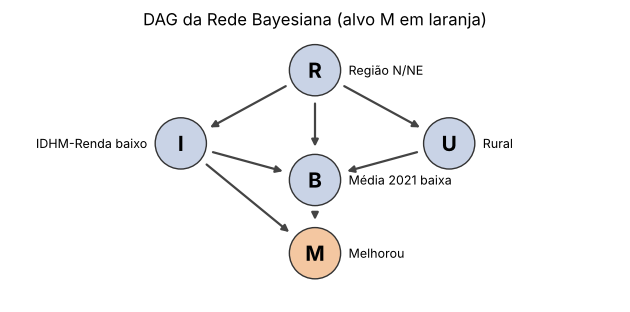

In [7]:
# Desenho do DAG
pos = {'R': (0, 3), 'I': (-2.2, 1.8), 'U': (2.2, 1.8), 'B': (0, 1.2), 'M': (0, 0)}
fig, ax = plt.subplots(figsize=(6.4, 4.4))
for p, n in ARESTAS:
    ax.annotate('', xy=pos[n], xytext=pos[p], arrowprops=dict(arrowstyle='-|>', lw=1.6, color='#444', shrinkA=24, shrinkB=24,
                                                           connectionstyle='arc3,rad=0.0'))
for n, (x_, y_) in pos.items():
    ax.add_patch(plt.Circle((x_, y_), .42, color='#c9d3e6' if n != 'M' else '#f4c7a1', ec='#333', zorder=3)); ax.text(x_, y_, n, ha='center', va='center', fontsize=15, weight='bold', zorder=4)
    ax.text(x_ + (-.55 if n == 'I' else .55), y_, NOMES[n], ha='right' if n == 'I' else 'left', va='center', fontsize=9, zorder=4)
ax.set_xlim(-5, 5); ax.set_ylim(-.8, 3.6); ax.set_aspect('equal'); ax.axis('off'); ax.set_title('DAG da Rede Bayesiana (alvo M em laranja)')
plt.tight_layout(); plt.show()

## 2. CPTs estimadas dos dados (Tarefa 2)
Cada nó guarda $P(\text{nó}\mid\text{pais})$: uma linha por combinação de valores dos pais. A estimativa é a frequência relativa com **suavização de Laplace** ($\alpha=1$, o MAP da Etapa 4):

$$P(X=1\mid \text{pa}=u)=\frac{N_{X=1,u}+\alpha}{N_u+2\alpha}$$

A distribuição conjunta passa a ser dada pela **regra da cadeia** (Etapa 3): $P(R,I,U,B,M)=P(R)\,P(I\mid R)\,P(U\mid R)\,P(B\mid R,I,U)\,P(M\mid B,I)$.

In [8]:
rede = BayesNet(PAIS).fit(d, alpha=1.0)
def mostra_cpt(rede, n):
    pa = rede.parents[n]
    t = pd.DataFrame([dict(zip(pa, c), **{f'P({n}=1|pais)': rede.cpt[n][c][1], 'n linhas': int(np.all([d[p].values == v for p, v in zip(pa, c)], axis=0).sum()) if pa else len(d)})
                      for c in rede.cpt[n]])
    print(f'CPT de {n} ({NOMES[n]}), pais = {pa or "—"}'); print(t.round(3).to_string(index=False)); print()
for n in rede.nodes: mostra_cpt(rede, n)

CPT de R (Região N/NE), pais = —
 P(R=1|pais)  n linhas
       0.379      3519

CPT de I (IDHM-Renda baixo), pais = ['R']
 R  P(I=1|pais)  n linhas
 0        0.055      2184
 1        0.770      1335

CPT de U (Rural), pais = ['R']
 R  P(U=1|pais)  n linhas
 0        0.118      2184
 1        0.212      1335

CPT de B (Média 2021 baixa), pais = ['R', 'I', 'U']
 R  I  U  P(B=1|pais)  n linhas
 0  0  0        0.289      1837
 0  0  1        0.389       227
 0  1  0        0.747        89
 0  1  1        0.727        31
 1  0  0        0.690       246
 1  0  1        0.855        60
 1  1  0        0.724       807
 1  1  1        0.830       222

CPT de M (Melhorou), pais = ['B', 'I']
 B  I  P(M=1|pais)  n linhas
 0  0        0.418      1530
 0  1        0.498       289
 1  0        0.804       840
 1  1        0.885       860



**Leitura:** a CPT de `M` mostra a regressão à média em números: com média inicial baixa (B=1) a chance de melhorar é alta (0,80 a 0,89, conforme o IDHM) e com média inicial não baixa (B=0) é bem menor (0,42 a 0,50). A de `I` mostra o contraste regional: 77% dos municípios do Norte/Nordeste têm IDHM-Renda baixo, contra 5,5% nos demais. Linhas com poucos exemplos (coluna `n linhas`) têm estimativas mais incertas; a suavização evita probabilidades 0 ou 1.

## 3. Inferência por enumeração (Tarefa 3)
Para uma consulta $P(Q\mid e)$: somamos a conjunta sobre todas as variáveis **ocultas** $H$ (as que não são $Q$ nem evidência) e normalizamos:

$$P(Q=q\mid e)=\frac{\sum_{h}P(q,e,h)}{\sum_{q'}\sum_{h}P(q',e,h)}$$

A conjunta de cada atribuição completa vem da regra da cadeia (produto das CPTs). Com 5 variáveis binárias são só 32 eventos atômicos, então enumerar tudo é barato.

In [9]:
# Sanidade: a conjunta construída pelas CPTs soma 1 (32 eventos atômicos)
tot = sum(rede.joint(dict(zip(rede.nodes, v))) for v in itertools.product([0, 1], repeat=5))
print(f'Soma da conjunta sobre os 32 eventos atômicos = {tot:.6f}')

CONSULTAS = [
    ('M', {}),                                    # prior: P(melhorou)
    ('M', {'B': 1}),                              # causal/previsão
    ('M', {'B': 0}),
    ('M', {'R': 1, 'U': 1}),                      # só região e ruralidade (B, I ocultos)
    ('M', {'R': 0, 'U': 0}),
    ('M', {'R': 1, 'I': 1, 'U': 1, 'B': 1}),      # evidência completa
    ('B', {'M': 1}),                              # diagnóstico (Bayes): melhorou ⇒ partiu de média baixa?
    ('I', {'M': 1, 'B': 1}),
    ('R', {'M': 1, 'B': 1, 'U': 0}),
]
for q, e in CONSULTAS:
    p = rede.query(q, e); ev = ', '.join(f'{k}={v}' for k, v in e.items()) or '∅'
    print(f'P({q}=1 | {ev:<22}) = {p[1]:.4f}')

Soma da conjunta sobre os 32 eventos atômicos = 1.000000
P(M=1 | ∅                     ) = 0.6309
P(M=1 | B=1                   ) = 0.8450
P(M=1 | B=0                   ) = 0.4307
P(M=1 | R=1, U=1              ) = 0.8031
P(M=1 | R=0, U=0              ) = 0.5436
P(M=1 | R=1, I=1, U=1, B=1    ) = 0.8852
P(B=1 | M=1                   ) = 0.6472
P(I=1 | M=1, B=1              ) = 0.5287
P(R=1 | M=1, B=1, U=0         ) = 0.5703


**Leitura:** sem evidência, P(melhorou) ≈ 0,63 (a marginal da Etapa 3). Sabendo só que o município é do N/NE e rural (e **sem** observar a média inicial nem o IDHM), a rede ainda propaga a evidência pelos caminhos `R → I → M`, `R → B → M` e `U → B → M` e resulta em ~0,80: é a inferência por enumeração somando sobre as variáveis ocultas `I` e `B`. A consulta `P(B=1 | M=1)` é a inferência **diagnóstica** (efeito → causa) da Etapa 3, agora dentro de uma rede maior.

## 4. Comparação com o pgmpy (Tarefa 4)
Construímos no pgmpy **o mesmo DAG com as mesmas CPTs** e rodamos `VariableElimination`. Também deixamos o pgmpy **estimar** as CPTs sozinho (`BayesianEstimator`, prior de Dirichlet com 1 pseudo-contagem, equivalente ao nosso Laplace) para comparar com as nossas.

In [10]:
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination
from pgmpy.estimators import BayesianEstimator

pg = DiscreteBayesianNetwork(ARESTAS)
for n, ps in PAIS.items():
    cols = list(itertools.product([0, 1], repeat=len(ps)))               # mesma ordem de colunas do pgmpy
    vals = np.array([[rede.cpt[n][c][v] for c in cols] for v in (0, 1)])
    pg.add_cpds(TabularCPD(n, 2, vals, evidence=ps or None, evidence_card=[2] * len(ps) if ps else None))
print('pgmpy check_model:', pg.check_model())
ve = VariableElimination(pg)

# 1) as consultas acima
difs = []
for q, e in CONSULTAS:
    p_pg = ve.query([q], evidence=e, show_progress=False).values; difs.append(np.abs(p_pg - rede.query(q, e)).max())
print(f'{len(CONSULTAS)} consultas listadas: máx |enumeração − pgmpy| = {max(difs):.2e}')

# 2) bateria exaustiva: toda variável de consulta × todo subconjunto de evidência × todos os valores
n_cons, dmax = 0, 0.0
for q in rede.nodes:
    outros = [v for v in rede.nodes if v != q]
    for r in range(0, 5):
        for ev_vars in itertools.combinations(outros, r):
            for vals in itertools.product([0, 1], repeat=r):
                e = dict(zip(ev_vars, vals))
                if rede.prob_evidence(e) < 1e-12: continue
                dmax = max(dmax, np.abs(ve.query([q], evidence=e, show_progress=False).values - rede.query(q, e)).max()); n_cons += 1
print(f'Bateria exaustiva: {n_cons} consultas P(Q | evidência), máx |enumeração − pgmpy| = {dmax:.2e}')

# 3) CPTs estimadas pelo pgmpy x as nossas
pg_fit = DiscreteBayesianNetwork(ARESTAS)
cpds_pg = {c.variable: c for c in BayesianEstimator(pg_fit, d).get_parameters(prior_type='dirichlet', pseudo_counts=1)}
def cpt_pgmpy_na_nossa_ordem(cpd, n):
    ordem = [n] + PAIS[n]; perm = [cpd.variables.index(v) for v in ordem]      # o pgmpy pode ordenar os pais de outro jeito
    return np.transpose(cpd.values, perm).reshape(2, -1)
dc = max(np.abs(cpt_pgmpy_na_nossa_ordem(cpds_pg[n], n) - np.array([[rede.cpt[n][c][v] for c in itertools.product([0, 1], repeat=len(PAIS[n]))] for v in (0, 1)])).max() for n in rede.nodes)
print(f'CPTs estimadas: máx |nossas − pgmpy| = {dc:.2e}')

pgmpy check_model: True
9 consultas listadas: máx |enumeração − pgmpy| = 1.11e-16
Bateria exaustiva: 405 consultas P(Q | evidência), máx |enumeração − pgmpy| = 2.22e-16
CPTs estimadas: máx |nossas − pgmpy| = 5.55e-17


**Resultado:** a enumeração do zero dá **o mesmo resultado do pgmpy** (diferença da ordem de 1e-16, só ruído de ponto flutuante) em todas as consultas, e as CPTs estimadas também coincidem. A diferença é de custo: a enumeração soma sobre todas as atribuições das variáveis ocultas (exponencial no nº delas), enquanto a eliminação de variáveis reaproveita somas parciais. Com 5 variáveis isso é irrelevante; em redes grandes, é o que torna a inferência viável.

## 5. d-separação (Tarefa 5)
Duas variáveis são **d-separadas** por $Z$ se todo caminho entre elas está bloqueado:
- **cadeia** $A\to C\to B$ e **bifurcação** $A\leftarrow C\to B$: bloqueados se $C\in Z$;
- **colisor** $A\to C\leftarrow B$: bloqueado se nem $C$ nem seus descendentes estão em $Z$ (**observar o colisor ou um descendente abre o caminho**).

Implementamos o teste do zero (grafo moral ancestral) e o validamos contra o pgmpy em **todas** as combinações (par, conjunto condicionante) do DAG.

In [11]:
# Validação do nosso teste de d-separação contra o pgmpy: todos os pares x todos os conjuntos Z possíveis
tot, ok = 0, 0
for X_, Y_ in itertools.combinations(rede.nodes, 2):
    resto = [v for v in rede.nodes if v not in (X_, Y_)]
    for r in range(len(resto) + 1):
        for Z_ in itertools.combinations(resto, r):
            meu = d_separados(PAIS, [X_], [Y_], Z_)
            pgm = Y_ not in pg.active_trail_nodes(X_, observed=list(Z_))[X_]      # pgmpy: Y alcançável = d-conectados
            tot += 1; ok += (meu == pgm)
print(f'Nosso d_separados == pgmpy em {ok}/{tot} casos (pares × conjuntos condicionantes).')

Nosso d_separados == pgmpy em 80/80 casos (pares × conjuntos condicionantes).


### 5.1 Duas independências condicionais, derivadas do DAG e testadas nos dados
Se o DAG está certo, as independências lidas dele devem aparecer nos dados (**informação mútua condicional ≈ 0**). Escolhemos duas sobre o alvo `M`:

1. **M ⊥ R | {B, I}**: dados a média inicial e o IDHM, a região não traz nada novo sobre a melhora (todos os caminhos de R até M passam por B ou I).
2. **M ⊥ U | {B, I}**: o mesmo para a ruralidade.

Para contraste, mostramos um conjunto condicionante que **não** separa (`{B}` sozinho deixa o caminho `R → I → M` aberto).

In [12]:
from scipy.stats import chi2
def testa(X_, Y_, Z_):
    ds = d_separados(PAIS, [X_], [Y_], Z_)
    cmi = info_mutua_cond(d, X_, Y_, Z_); gl = 2 ** len(Z_)                      # 1 grau de liberdade por estrato (var. binárias)
    G = 2 * len(d) * np.log(2) * cmi; p = chi2.sf(G, gl)                        # teste G: 2 N ln2 · I ~ χ²(gl) sob independência
    return {'afirmação': f'{X_} ⊥ {Y_} | {{{", ".join(Z_)}}}', 'DAG diz': 'd-separados' if ds else 'd-conectados', 'I(X;Y|Z) bits': cmi, 'estat. G': G, 'p-valor': p}
tab_ind = pd.DataFrame([testa('M', 'R', ['B', 'I']), testa('M', 'U', ['B', 'I']),
                        testa('M', 'R', ['B']), testa('M', 'R', []), testa('M', 'U', ['B'])]).set_index('afirmação')
print(tab_ind.round(4).to_string())

                     DAG diz  I(X;Y|Z) bits  estat. G  p-valor
afirmação                                                     
M ⊥ R | {B, I}   d-separados         0.0014    6.8645   0.1432
M ⊥ U | {B, I}   d-separados         0.0009    4.5653   0.3349
M ⊥ R | {B}     d-conectados         0.0053   25.8866   0.0000
M ⊥ R | {}      d-conectados         0.0435  212.3490   0.0000
M ⊥ U | {B}     d-conectados         0.0007    3.2668   0.1953


**Leitura:** nas duas independências derivadas do DAG, a informação mútua condicional é minúscula (≈ 0,001 bit) e o teste G **não rejeita** a independência (p-valor alto), como a rede prevê. No contraste, em `M ⊥ R | {B}` o DAG diz *d-conectados* e os dados concordam (informação mútua maior, p-valor ≈ 0): sem condicionar em `I`, a região ainda informa sobre `M`. Já em `M ⊥ U | {B}` o DAG permite dependência, mas ela é pequena demais para o teste detectar (p = 0,20): d-conectados significa "pode haver dependência", não "há dependência forte". O teste G supõe exemplos independentes, o que não vale exatamente aqui (um município pode aparecer em várias linhas), então tratamos os p-valores como **indicação**, e a magnitude da informação mútua como o dado mais robusto.

### 5.2 Colisor: observar o efeito "abre o caminho"
No DAG, `B` é um **colisor** no caminho $I\to B\leftarrow U$. Já `I` e `U` só se ligam por `R` (bifurcação $I\leftarrow R\to U$). Logo:

- `I ⊥ U | R` (ao condicionar na região, o caminho pela bifurcação fecha e o do colisor está bloqueado);
- `I ⊥̸ U | {R, B}` (**observar B abre o caminho do colisor**: "explaining away").

Intuição: se sabemos que a média inicial é baixa (B=1), saber que o município é rural já "explica" a média baixa e muda nossa crença sobre a renda.

In [13]:
print('d-separação no DAG:  I ⊥ U | {R}    →', d_separados(PAIS, ['I'], ['U'], ['R']),
      '|  I ⊥ U | {R,B} →', d_separados(PAIS, ['I'], ['U'], ['R', 'B']), '|  I ⊥ U | {R,M} →', d_separados(PAIS, ['I'], ['U'], ['R', 'M']), '(M é descendente de B)')

# Efeito da evidência em U sobre a crença em I, com e sem observar o colisor B (inferência por enumeração na rede)
lin = []
for r in (0, 1):
    for b in (None, 0, 1):
        base = {'R': r} if b is None else {'R': r, 'B': b}
        p_u0 = rede.query('I', {**base, 'U': 0})[1]; p_u1 = rede.query('I', {**base, 'U': 1})[1]
        lin.append({'R': r, 'B observado?': 'não' if b is None else f'sim (B={b})', 'P(I=1|…,U=0)': p_u0, 'P(I=1|…,U=1)': p_u1, 'diferença': p_u1 - p_u0})
col = pd.DataFrame(lin); print('\n' + col.round(4).to_string(index=False))

# Mesma ideia em termos de informação mútua calculada DENTRO do modelo (distribuição conjunta da rede)
joint = pd.DataFrame([dict(zip(rede.nodes, v), p=rede.joint(dict(zip(rede.nodes, v)))) for v in itertools.product([0, 1], repeat=5)])
def cmi_modelo(a, b, cond):
    tot_ = 0.0
    for _, g in (joint.groupby(cond) if cond else [((), joint)]):
        pg_ = g.p.sum(); t = g.groupby([a, b]).p.sum().unstack().reindex(index=[0, 1], columns=[0, 1], fill_value=0).values / pg_
        pa, pb = t.sum(1, keepdims=True), t.sum(0, keepdims=True)
        with np.errstate(all='ignore'): tot_ += pg_ * np.nansum(np.where(t > 0, t * np.log2(t / (pa * pb)), 0))
    return tot_
print(f"\nNo modelo:  I(I;U | R) = {abs(cmi_modelo('I', 'U', ['R'])):.6f} bits   |   I(I;U | R,B) = {cmi_modelo('I', 'U', ['R', 'B']):.6f} bits")

d-separação no DAG:  I ⊥ U | {R}    → True |  I ⊥ U | {R,B} → False |  I ⊥ U | {R,M} → False (M é descendente de B)

 R B observado?  P(I=1|…,U=0)  P(I=1|…,U=1)  diferença
 0          não        0.0554        0.0554     0.0000
 0    sim (B=0)        0.0204        0.0255     0.0051
 0    sim (B=1)        0.1317        0.0988    -0.0329
 1          não        0.7704        0.7704     0.0000
 1    sim (B=0)        0.7487        0.7968     0.0481
 1    sim (B=1)        0.7790        0.7652    -0.0138

No modelo:  I(I;U | R) = 0.000000 bits   |   I(I;U | R,B) = 0.000370 bits


**Leitura:** com `R` fixo e `B` **não** observado, a diferença na crença sobre `I` ao saber `U` é **exatamente 0** (e a informação mútua dentro do modelo é 0): `I` e `U` são independentes. Ao **observar o colisor `B`**, a diferença deixa de ser 0 (até ±5 pontos percentuais, com sinal que depende de `R` e `B`) e a informação mútua passa a ser positiva: o caminho `I → B ← U` abriu. O efeito é **modesto** porque `U` pesa pouco sobre `B` nos dados (cf. CPT de `B` e o ΔBIC da Seção 1), mas o mecanismo é o do enunciado: **observar o efeito comum cria dependência entre as causas**. O mesmo vale se observarmos `M`, descendente de `B`.

## 6. Economia de parâmetros (Tarefa 6)
Para $n$ variáveis binárias, a conjunta completa tem $2^n-1$ parâmetros livres. Na rede, cada nó com $k$ pais precisa de $2^k$ (uma probabilidade por linha da CPT).

In [14]:
linhas = [{'nó': n, 'pais': ', '.join(PAIS[n]) or '—', 'parâmetros livres': 2 ** len(PAIS[n])} for n in rede.nodes]
tp = pd.DataFrame(linhas); print(tp.to_string(index=False))
conj, redep = n_params_conjunta(5), rede.n_params()
print(f'\nConjunta completa: 2^5 − 1 = {conj} parâmetros')
print(f'Rede Bayesiana:    {redep} parâmetros  (nº calculado por BayesNet.n_params(): {rede.n_params()})')
print(f'Economia: {conj - redep} parâmetros ({1 - redep / conj:.0%} a menos) + a estrutura (o DAG)')
print(f'\nO maior ganho vem de P(B|R,I,U) (8 parâmetros) e P(M|B,I) (4) no lugar de uma tabela única de 31 números.')

nó    pais  parâmetros livres
 R       —                  1
 I       R                  2
 U       R                  2
 B R, I, U                  8
 M    B, I                  4

Conjunta completa: 2^5 − 1 = 31 parâmetros
Rede Bayesiana:    17 parâmetros  (nº calculado por BayesNet.n_params(): 17)
Economia: 14 parâmetros (45% a menos) + a estrutura (o DAG)

O maior ganho vem de P(B|R,I,U) (8 parâmetros) e P(M|B,I) (4) no lugar de uma tabela única de 31 números.


**Leitura:** a rede usa **17** parâmetros contra **31** da conjunta (≈ 45% a menos). É menos que a economia "~10" do exemplo do enunciado porque nosso DAG é mais denso (um nó com 3 pais, `B`, custa 8). Em 5 variáveis a economia é modesta; ela cresce de forma exponencial com o nº de variáveis, desde que cada nó tenha poucos pais (com 20 variáveis binárias a conjunta teria ~1 milhão de parâmetros).

## 7. A rede como classificador de `ALVO_MELHORA` (ligação com o pipeline)
Usamos a rede para prever $M$ a partir da evidência $(R,I,U,B)$: $\hat M=\arg\max_m P(M=m\mid R,I,U,B)$, por enumeração. As CPTs são estimadas **só no treino** de cada partição, com as **mesmas 5 partições agrupadas por município** das Etapas 1, 2 e 4. Como $M\perp R,U\mid\{B,I\}$ (Seção 5), a previsão depende só de $B$ e $I$ (os pais de $M$): o restante da evidência é irrelevante para o alvo.

In [15]:
def kfold_por_grupo(y, grupos, k=5, seed=SEED):
    # 5-fold agrupado por município (mesma função das Etapas 1, 2 e 4)
    rng = np.random.RandomState(seed); y = np.asarray(y); grupos = np.asarray(grupos)
    ids = pd.unique(grupos); rng.shuffle(ids)
    info = pd.DataFrame({'g': grupos, 'y': y}).groupby('g').y.agg(['size', 'sum']).loc[ids]
    info = info.sort_values('size', ascending=False, kind='stable')
    tam, pos, dest, p1 = np.zeros(k), np.zeros(k), {}, y.mean()
    for g, (n, s_) in info.iterrows():
        f = min(range(k), key=lambda j: (tam[j], pos[j] - p1 * tam[j]))
        dest[g] = f; tam[f] += n; pos[f] += s_
    fold = np.array([dest[g] for g in grupos])
    return [(np.where(fold != j)[0], np.where(fold == j)[0]) for j in range(k)]

y = d.M.values; folds = kfold_por_grupo(y, groups)
print('municípios disjuntos entre treino e teste:', all(set(groups[a]).isdisjoint(groups[b]) for a, b in folds))
BASELINE = float(np.mean([(y[te] == np.bincount(y[tr]).argmax()).mean() for tr, te in folds]))

def acc_rede(pais, evid_vars):
    te_acc, tr_acc = [], []
    for tr, te in folds:
        rd = BayesNet(pais).fit(d.iloc[tr]); cache = {}
        def pred(rows):
            out = []
            for tup in map(tuple, rows[evid_vars].values):
                if tup not in cache: cache[tup] = int(rd.query('M', dict(zip(evid_vars, tup)))[1] >= 0.5)
                out.append(cache[tup])
            return np.array(out)
        te_acc.append((pred(d.iloc[te]) == y[te]).mean()); tr_acc.append((pred(d.iloc[tr]) == y[tr]).mean())
    return np.array(te_acc), np.array(tr_acc)

te_a, tr_a = acc_rede(PAIS, ['R', 'I', 'U', 'B'])
te_b, _ = acc_rede({'R': [], 'I': ['R'], 'U': ['R'], 'B': ['R', 'I', 'U'], 'M': ['B']}, ['R', 'I', 'U', 'B'])     # sem I → M
print(f'Baseline majoritário:                      {BASELINE:.4f}')
print(f'Rede Bayesiana (DAG proposto), 5-fold:     {te_a.mean():.4f} ± {te_a.std():.4f}  (treino {tr_a.mean():.4f}) | por partição: {te_a.round(3)}')
print(f'Rede sem a aresta I → M, 5-fold:           {te_b.mean():.4f} ± {te_b.std():.4f}')
print('\nReferências das etapas anteriores (mesmas partições): árvore ≈ 0,739 | logística ≈ 0,741 | Naive Bayes 0,712 | Naive Bayes + EM (K=3) 0,734')

municípios disjuntos entre treino e teste: True


Baseline majoritário:                      0.6311
Rede Bayesiana (DAG proposto), 5-fold:     0.6968 ± 0.0163  (treino 0.7045) | por partição: [0.7   0.676 0.683 0.701 0.723]
Rede sem a aresta I → M, 5-fold:           0.7030 ± 0.0155

Referências das etapas anteriores (mesmas partições): árvore ≈ 0,739 | logística ≈ 0,741 | Naive Bayes 0,712 | Naive Bayes + EM (K=3) 0,734


In [16]:
resumo = pd.DataFrame({'Acurácia teste (5-fold)': [BASELINE, 0.7119, 0.7343, te_a.mean()],
                       'Parâmetros livres': [1, 73, 221, rede.n_params()]},
                      index=['Baseline majoritário', 'Naive Bayes puro (Etapa 4)', 'Naive Bayes + EM, K=3 (Etapa 4)', 'Rede Bayesiana (Etapa 5)'])
print(resumo.round(4).to_string())

                                 Acurácia teste (5-fold)  Parâmetros livres
Baseline majoritário                              0.6311                  1
Naive Bayes puro (Etapa 4)                        0.7119                 73
Naive Bayes + EM, K=3 (Etapa 4)                   0.7343                221
Rede Bayesiana (Etapa 5)                          0.6968                 17


## 8. Discussão e resumo

| Item | Resultado |
|---|---|
| DAG | 5 nós (R, I, U, B, M), 7 arestas; BIC aponta 6 arestas claramente úteis e `U → B` como empate técnico |
| CPTs | estimadas por frequência com Laplace (α=1); coincidem com as do pgmpy |
| Enumeração × pgmpy | diferença ≤ 2,2e-16 em 405 consultas exaustivas + 9 listadas |
| d-separação | nosso teste = pgmpy em 80/80 casos; `M ⊥ R \| {B,I}` e `M ⊥ U \| {B,I}` confirmadas nos dados (informação mútua ≈ 0,001 bit) |
| Colisor | `I ⊥ U \| R`, mas `I ⊥̸ U \| {R,B}`: observar `B` abre o caminho (efeito modesto) |
| Parâmetros | 17 contra 31 da conjunta (−45%) |
| Rede como classificador de `ALVO_MELHORA` | **69,7%** ± 1,6 (baseline 63,1%) |

- **A rede faz o que o enunciado pede:** captura dependências coerentes com o domínio (região → renda → desempenho → melhora), responde consultas em qualquer direção (previsão `P(M|B)`, diagnóstico `P(B|M)`, evidência parcial) e a inferência por enumeração do zero coincide com a do pgmpy até o ruído de ponto flutuante.
- **d-separação como verificação do modelo:** as independências lidas do grafo não ficam só no papel: dadas a média inicial e o IDHM, nem a região nem a ruralidade informam sobre a melhora (p = 0,14 e 0,33), enquanto condicionar só em `B` deixa `R` informativa (o caminho `R → I → M` segue aberto). Isso sustenta a aresta `I → M`.
- **Como classificador, a rede não é a melhor:** 69,7% fica abaixo do Naive Bayes (71,2%), do NB+EM (73,4%), da árvore (≈ 73,9%) e da logística (≈ 74,1%). Isso era esperado: a rede usa variáveis **binarizadas** (média inicial < 265 em vez de 4 faixas; sem as 27 UFs) e, por causa da independência `M ⊥ R,U | {B,I}`, só `B` e `I` entram na decisão. Em troca usa só **17 parâmetros** (contra 73 do Naive Bayes e 221 do NB+EM) e é totalmente interpretável. O ganho da rede está na **inferência e na explicação**, não na acurácia; o ganho sobre o baseline (+6,6 p.p.) mostra que o sinal de `B` e `I` é real.
- **Aresta `I → M`:** o BIC a favorece (ΔBIC = −5,9 ao remover), mas na classificação ela não ajuda (70,3% sem ela contra 69,7% com ela): a diferença é menor que o desvio entre partições, e a decisão `P(M=1|B=0,I=1) ≈ 0,50` fica no limite de 0,5, onde qualquer variação de treino troca a classe.
- **Frente ao "gabarito" do enunciado:** os critérios qualitativos foram atendidos: DAG coerente, enumeração idêntica ao pgmpy e um caso de colisor demonstrado. A economia de parâmetros (31 → 17) é menor que os "~10" do exemplo porque o nó `B` tem 3 pais.

**Limitações para o relatório**
1. As arestas são **associações com direção dada pelo domínio e pela ordem temporal**, não efeitos causais. Em especial, `B → M` é em grande parte regressão à média (Etapas 1 a 3), não efeito do Novo Ensino Médio.
2. `U → B` é um empate técnico no BIC e `I → U`/`U → I` também; o DAG não é o único compatível com os dados (estruturas equivalentes e quase equivalentes existem). A aresta `U → B` foi mantida por razão de domínio e para o colisor, e o efeito do colisor é pequeno (informação mútua ≈ 0,0004 bit).
3. Binarizar perde informação; um DAG com `FAIXA_MEDIA_2021` em 4 níveis e nós não binários (CPTs maiores) tenderia a classificar melhor, ao custo de mais parâmetros. Os limiares (0,6 para IDHM, 265 para a média) são os da Etapa 3.
4. Os p-valores do teste G assumem exemplos independentes, o que não vale exatamente (um município pode ter várias linhas); servem de indicação, junto com a magnitude da informação mútua.
5. **Próxima etapa:** a probabilidade `P(M | evidência)` calculada pela rede (e a probabilidade do Naive Bayes da Etapa 4) podem alimentar as regras Se-Então do sistema **fuzzy** (Etapa 6) para produzir a decisão final interpretável.


## 9. Exportar tabelas para o LaTeX

In [17]:
lat = resumo.copy(); lat.index = [i.replace('%', r'\\%') for i in lat.index]
print(lat.round(3).to_latex(float_format='%.3f', caption='Etapa 5: Rede Bayesiana como classificador (5-fold agrupado por município).', label='tab:etapa5'))
print(tp.to_latex(index=False, caption='Parâmetros livres por nó da Rede Bayesiana.', label='tab:params'))

\begin{table}
\caption{Etapa 5: Rede Bayesiana como classificador (5-fold agrupado por município).}
\label{tab:etapa5}
\begin{tabular}{lrr}
\toprule
 & Acurácia teste (5-fold) & Parâmetros livres \\
\midrule
Baseline majoritário & 0.631 & 1 \\
Naive Bayes puro (Etapa 4) & 0.712 & 73 \\
Naive Bayes + EM, K=3 (Etapa 4) & 0.734 & 221 \\
Rede Bayesiana (Etapa 5) & 0.697 & 17 \\
\bottomrule
\end{tabular}
\end{table}

\begin{table}
\caption{Parâmetros livres por nó da Rede Bayesiana.}
\label{tab:params}
\begin{tabular}{llr}
\toprule
nó & pais & parâmetros livres \\
\midrule
R & — & 1 \\
I & R & 2 \\
U & R & 2 \\
B & R, I, U & 8 \\
M & B, I & 4 \\
\bottomrule
\end{tabular}
\end{table}

